# Notebook 3: Random Forest (Pair B)

<div dir="rtl" align="right">

يبني هذا الملف نموذج Random Forest لتوقع مغادرة العملاء. يتكون من جزأين: الجزء الأول يجهّز النموذج ويدرّبه، والجزء الثاني يضبط الإعدادات ويختار حد التصنيف ويقيّم النموذج النهائي على بيانات الاختبار.

</div>

## Part A: Pipeline and Training

<div dir="rtl" align="right">

يشمل هذا الجزء قراءة البيانات المقسّمة، وتجهيز خطوات المعالجة، وتدريب نموذج أولي.

</div>

### 1. Import Libraries

<div dir="rtl" align="right">

تستورد الخلية التالية المكتبات المطلوبة لبناء النموذج وتقييمه ورسم النتائج.

</div>

In [1]:
# os is used to create folders
import os
# numpy is used for numeric operations
import numpy as np
# pandas is used to read and handle data tables
import pandas as pd
# matplotlib is used to draw charts
import matplotlib.pyplot as plt
# the Random Forest classifier
from sklearn.ensemble import RandomForestClassifier
# OneHotEncoder converts categories into 0/1 columns
from sklearn.preprocessing import OneHotEncoder
# ColumnTransformer applies a step to selected columns only
from sklearn.compose import ColumnTransformer
# Pipeline joins the preprocessing and the model in one object
from sklearn.pipeline import Pipeline
# metrics used to evaluate the model
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
# ranking metrics and the confusion matrix
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
# tool for drawing the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
# permutation importance is used to interpret the model
from sklearn.inspection import permutation_importance

### 2. Set Paths and Constants

<div dir="rtl" align="right">

تحدد الخلية التالية مجلد البيانات المقسّمة ومجلد النتائج، وتثبّت الرقم العشوائي 433، وتعرّف أسماء الأعمدة المستخدمة.

</div>

<div dir="rtl" align="right">

تربط الخلية التالية Google Drive مع Colab وتحدد مجلد المشروع `churn_project` في My Drive. جميع المسارات بعد ذلك مبنية على هذا المجلد، لذلك تُحفظ كل النتائج في Drive.

</div>

In [2]:
# tool that connects Google Drive to Colab
from google.colab import drive
# connect Google Drive (Colab asks for permission the first time)
drive.mount("/content/drive")
# project folder inside Google Drive
BASE_FOLDER = "/content/drive/MyDrive/churn_project"
# print the project folder that will be used
print("Project folder:", BASE_FOLDER)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/churn_project


In [3]:
# folder that contains the split files from Notebook 1
SPLIT_FOLDER = BASE_FOLDER + "/data/splits"
# folder where the results will be saved
RESULTS_FOLDER = BASE_FOLDER + "/results"
# fixed random seed so the results can be reproduced
SEED = 433
# create the results folder if it does not exist
os.makedirs(RESULTS_FOLDER, exist_ok=True)
# numeric features (used as they are)
NUMERIC_FEATURES = [
    "Call Failure",
    "Subscription Length",
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS",
    "Distinct Called Numbers",
    "Complains",
]
# categorical features (will be one-hot encoded)
CATEGORICAL_FEATURES = ["Charge Amount", "Tariff Plan", "Status"]
# all ten input features
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
# name of the target column
TARGET = "Churn"

### 3. Load the Shared Split

<div dir="rtl" align="right">

تقرأ الخلية التالية ملفات التدريب والتحقق والاختبار التي تم حفظها في Notebook 1، وهي نفس الملفات المستخدمة مع Logistic Regression.

</div>

In [4]:
# read the training data
train = pd.read_csv(SPLIT_FOLDER + "/train.csv")
# read the validation data
val = pd.read_csv(SPLIT_FOLDER + "/validation.csv")
# read the test data
test = pd.read_csv(SPLIT_FOLDER + "/test.csv")
# print the number of rows in each part
print("Train:", len(train), "| Validation:", len(val), "| Test:", len(test))

Train: 2201 | Validation: 482 | Test: 467


### 4. Separate Features and Target

<div dir="rtl" align="right">

تفصل الخلية التالية الخصائص (X) عن عمود الهدف (y) في كل جزء من البيانات.

</div>

In [5]:
# input features of the training data
X_train = train[FEATURES]
# target of the training data
y_train = train[TARGET]
# input features of the validation data
X_val = val[FEATURES]
# target of the validation data
y_val = val[TARGET]
# input features of the test data
X_test = test[FEATURES]
# target of the test data
y_test = test[TARGET]

### 5. Define the Preprocessing Step

<div dir="rtl" align="right">

تعرّف الخلية التالية خطوة المعالجة: تحويل الأعمدة الفئوية الثلاثة إلى أعمدة 0/1 (one-hot)، وترك باقي الأعمدة كما هي. لا يحتاج Random Forest إلى توحيد مقياس الأرقام (scaling).

</div>

In [6]:
# one-hot encode the categorical columns and pass the other columns unchanged
preprocessing = ColumnTransformer(
    transformers=[("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)],
    remainder="passthrough",
)

### 6. Train a Baseline Random Forest

<div dir="rtl" align="right">

تبني الخلية التالية نموذجاً أولياً من 200 شجرة بالإعدادات الافتراضية، وتدرّبه على بيانات التدريب فقط. خطوة المعالجة موجودة داخل الـ pipeline، لذلك تتعلم من بيانات التدريب فقط ولا تتسرب إليها معلومات من التحقق أو الاختبار.

</div>

In [7]:
# build the pipeline: preprocessing followed by the Random Forest model
baseline_model = Pipeline(
    steps=[
        ("preprocessing", preprocessing),
        ("model", RandomForestClassifier(n_estimators=200, random_state=SEED)),
    ]
)
# train the pipeline on the training data only
baseline_model.fit(X_train, y_train)
# predict the churn probability for the validation customers
baseline_val_prob = baseline_model.predict_proba(X_val)[:, 1]
# calculate the Average Precision on the validation data
baseline_ap = average_precision_score(y_val, baseline_val_prob)
# print the baseline result
print("Baseline validation Average Precision:", round(baseline_ap, 4))

Baseline validation Average Precision: 0.8984


## Part B: Tuning, Threshold Selection, and Evaluation

<div dir="rtl" align="right">

يشمل هذا الجزء تجربة 12 إعداداً للنموذج، واختيار أفضلها، واختيار حد التصنيف، ثم التقييم النهائي على بيانات الاختبار وتفسير النموذج.

</div>

### 7. Define the Hyperparameter Grid

<div dir="rtl" align="right">

تنشئ الخلية التالية قائمة الإعدادات المطلوب تجربتها: 3 قيم لعمق الشجرة × قيمتان لأقل عدد عينات في الورقة × قيمتان لوزن الفئات = 12 إعداداً. عدد الأشجار ثابت عند 200.

</div>

In [8]:
# number of trees (fixed for all configurations)
N_TREES = 200
# values of the maximum tree depth (None means no limit)
depth_values = [5, 10, None]
# values of the minimum number of samples in a leaf
leaf_values = [2, 10]
# values of the class weight (None or balanced)
weight_values = [None, "balanced"]
# empty list that will hold all the configurations
configs = []
# loop over every depth value
for depth in depth_values:
    # loop over every leaf value
    for leaf in leaf_values:
        # loop over every class weight value
        for weight in weight_values:
            # add this combination to the list
            configs.append({"max_depth": depth, "min_samples_leaf": leaf, "class_weight": weight})
# print the number of configurations
print("Number of configurations:", len(configs))

Number of configurations: 12


### 8. Train and Evaluate Every Configuration

<div dir="rtl" align="right">

تدرّب الخلية التالية نموذجاً لكل إعداد على بيانات التدريب، ثم تحسب Average Precision على بيانات التحقق وتسجل النتيجة. بيانات الاختبار لا تُستخدم في هذه المرحلة.

</div>

In [9]:
# empty list that will hold the trained models
models = []
# empty list that will hold the result of each configuration
rows = []
# loop over the configurations with their index
for i, config in enumerate(configs):
    # build the pipeline with the settings of this configuration
    model = Pipeline(
        steps=[
            ("preprocessing", preprocessing),
            ("model", RandomForestClassifier(
                n_estimators=N_TREES,
                max_depth=config["max_depth"],
                min_samples_leaf=config["min_samples_leaf"],
                class_weight=config["class_weight"],
                random_state=SEED,
            )),
        ]
    )
    # train the pipeline on the training data only
    model.fit(X_train, y_train)
    # predict the churn probability for the validation customers
    val_prob = model.predict_proba(X_val)[:, 1]
    # calculate the Average Precision on the validation data
    val_ap = average_precision_score(y_val, val_prob)
    # keep the trained model
    models.append(model)
    # keep the settings and the score of this configuration
    rows.append({
        "config": i,
        "max_depth": str(config["max_depth"]),
        "min_samples_leaf": config["min_samples_leaf"],
        "class_weight": str(config["class_weight"]),
        "validation_ap": val_ap,
    })
# convert the results into a table
tuning_results = pd.DataFrame(rows)
# show the table
tuning_results

,config,max_depth,min_samples_leaf,class_weight,validation_ap
0,0,5,2,None,0.848444
1,1,5,2,balanced,0.799994
2,2,5,10,None,0.825585
3,3,5,10,balanced,0.782796
4,4,10,2,None,0.904215
5,5,10,2,balanced,0.851850
6,6,10,10,None,0.848500
7,7,10,10,balanced,0.818085
8,8,None,2,None,0.904162
9,9,None,2,balanced,0.868982


### 9. Select the Best Configuration

<div dir="rtl" align="right">

ترتب الخلية التالية الإعدادات من الأعلى إلى الأقل في Average Precision وتختار الأول. عند تساوي النتيجة يُفضَّل الإعداد الأبسط: عدد عينات أكبر في الورقة، ثم عمق أقل.

</div>

In [10]:
# create a numeric depth column for sorting (no limit is treated as a very large depth)
tuning_results["depth_order"] = tuning_results["max_depth"].replace("None", "999").astype(int)
# sort by highest AP, then larger leaf, then smaller depth
tuning_sorted = tuning_results.sort_values(
    by=["validation_ap", "min_samples_leaf", "depth_order"],
    ascending=[False, False, True],
)
# take the index of the first (best) configuration
best_index = int(tuning_sorted.iloc[0]["config"])
# get the settings of the best configuration
best_config = configs[best_index]
# get the trained model of the best configuration
best_model = models[best_index]
# print the selected settings
print("Best configuration:", best_config)
# print its validation score
print("Validation Average Precision:", round(tuning_sorted.iloc[0]["validation_ap"], 4))
# show the sorted table without the helper column
tuning_sorted.drop(columns="depth_order")

Best configuration: {'max_depth': 10, 'min_samples_leaf': 2, 'class_weight': None}
Validation Average Precision: 0.9042


,config,max_depth,min_samples_leaf,class_weight,validation_ap
4,4,10,2,None,0.904215
8,8,None,2,None,0.904162
9,9,None,2,balanced,0.868982
5,5,10,2,balanced,0.851850
6,6,10,10,None,0.848500
0,0,5,2,None,0.848444
10,10,None,10,None,0.846990
2,2,5,10,None,0.825585
11,11,None,10,balanced,0.818458
7,7,10,10,balanced,0.818085


### 10. Select the Classification Threshold

<div dir="rtl" align="right">

يعطي النموذج احتمالاً لكل عميل، ويحوّله حد التصنيف (threshold) إلى قرار: يغادر أو لا يغادر. تجرب الخلية التالية الحدود من 0.05 إلى 0.95 بزيادة 0.05 على بيانات التحقق، وتختار الحد الذي يعطي أعلى F1 لفئة المغادرين. عند التساوي يُختار الحد الأعلى.

</div>

In [11]:
# predict the churn probability for the validation customers with the best model
val_prob = best_model.predict_proba(X_val)[:, 1]
# list of thresholds from 0.05 to 0.95
thresholds = [round(t, 2) for t in np.arange(0.05, 0.96, 0.05)]
# empty list that will hold the F1 score of each threshold
f1_values = []
# start with no selected threshold
best_threshold = None
# start with the lowest possible F1 score
best_f1 = -1
# loop over every threshold
for t in thresholds:
    # predict churn when the probability is at or above the threshold
    val_pred = (val_prob >= t).astype(int)
    # calculate the F1 score of the churn class
    f1 = f1_score(y_val, val_pred, zero_division=0)
    # keep the F1 score for the chart
    f1_values.append(f1)
    # update the best threshold (>= keeps the higher threshold when scores are equal)
    if f1 >= best_f1:
        # save the new best F1 score
        best_f1 = f1
        # save the new best threshold
        best_threshold = t
# print the selected threshold
print("Selected threshold:", best_threshold)
# print its validation F1 score
print("Validation F1 at this threshold:", round(best_f1, 4))

Selected threshold: 0.55
Validation F1 at this threshold: 0.8101


### 11. Plot F1 Score Against the Threshold

<div dir="rtl" align="right">

ترسم الخلية التالية قيمة F1 عند كل حد، وتوضح الحد المختار بخط عمودي.

</div>

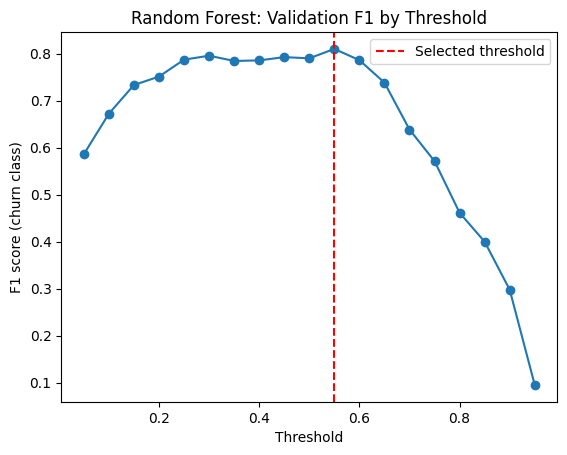

In [12]:
# draw the F1 score for every threshold
plt.plot(thresholds, f1_values, marker="o")
# draw a vertical line at the selected threshold
plt.axvline(best_threshold, color="red", linestyle="--", label="Selected threshold")
# set the chart title
plt.title("Random Forest: Validation F1 by Threshold")
# set the x-axis label
plt.xlabel("Threshold")
# set the y-axis label
plt.ylabel("F1 score (churn class)")
# show the legend
plt.legend()
# save the chart as an image
plt.savefig(RESULTS_FOLDER + "/rf_threshold_f1.png", dpi=150, bbox_inches="tight")
# display the chart
plt.show()

### 12. Final Evaluation on the Test Set

<div dir="rtl" align="right">

بعد تثبيت الإعدادات وحد التصنيف، تستخدم الخلية التالية بيانات الاختبار مرة واحدة فقط لحساب المقاييس النهائية: Precision و Recall و F1 و Accuracy و Average Precision و ROC-AUC.

</div>

In [13]:
# predict the churn probability for the test customers
test_prob = best_model.predict_proba(X_test)[:, 1]
# convert the probabilities into decisions using the selected threshold
test_pred = (test_prob >= best_threshold).astype(int)
# precision: share of predicted churners who really churned
precision = precision_score(y_test, test_pred)
# recall: share of real churners that the model detected
recall = recall_score(y_test, test_pred)
# F1: balance between precision and recall
f1 = f1_score(y_test, test_pred)
# accuracy: share of all correct predictions
accuracy = accuracy_score(y_test, test_pred)
# Average Precision: ranking quality across all thresholds
ap = average_precision_score(y_test, test_prob)
# ROC-AUC: ability to rank churners above non-churners
roc_auc = roc_auc_score(y_test, test_prob)
# print the precision
print("Precision:", round(precision, 4))
# print the recall
print("Recall:", round(recall, 4))
# print the F1 score
print("F1 score:", round(f1, 4))
# print the accuracy
print("Accuracy:", round(accuracy, 4))
# print the Average Precision
print("Average Precision:", round(ap, 4))
# print the ROC-AUC
print("ROC-AUC:", round(roc_auc, 4))

Precision: 0.9302
Recall: 0.5797
F1 score: 0.7143
Accuracy: 0.9315
Average Precision: 0.9147
ROC-AUC: 0.9796


### 13. Confusion Matrix

<div dir="rtl" align="right">

تحسب الخلية التالية مصفوفة الالتباس على بيانات الاختبار وترسمها. توضح المصفوفة عدد المغادرين الذين اكتشفهم النموذج (TP)، والذين لم يكتشفهم (FN)، والتنبيهات الخاطئة (FP)، وغير المغادرين المصنفين بشكل صحيح (TN).

</div>

TN: 395 | FP: 3 | FN: 29 | TP: 40


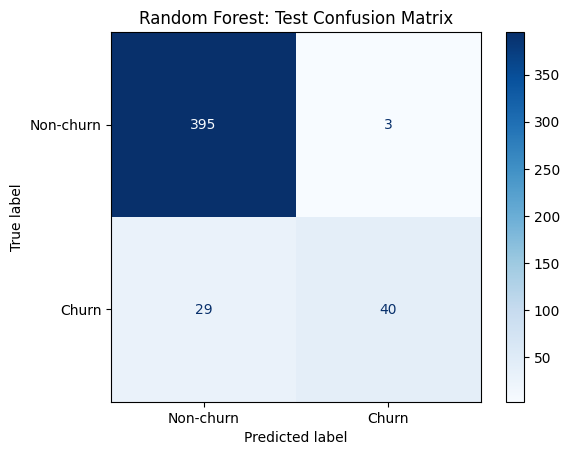

In [14]:
# calculate the confusion matrix
cm = confusion_matrix(y_test, test_pred)
# read the four numbers from the matrix
tn, fp, fn, tp = cm.ravel()
# print the four numbers
print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)
# prepare the confusion matrix chart
display = ConfusionMatrixDisplay(cm, display_labels=["Non-churn", "Churn"])
# draw the chart
display.plot(cmap="Blues")
# set the chart title
plt.title("Random Forest: Test Confusion Matrix")
# save the chart as an image
plt.savefig(RESULTS_FOLDER + "/rf_confusion_matrix.png", dpi=150, bbox_inches="tight")
# display the chart
plt.show()

### 14. Model Interpretation (Permutation Importance)

<div dir="rtl" align="right">

تقيس الخلية التالية أهمية كل خاصية بطريقة permutation importance على بيانات التحقق: تُخلط قيم الخاصية عشوائياً ويُحسب مقدار انخفاض Average Precision. كلما كان الانخفاض أكبر كانت الخاصية أهم للتوقع. هذه النتائج تدل على ارتباط تنبؤي وليست دليلاً على علاقة سببية.

</div>

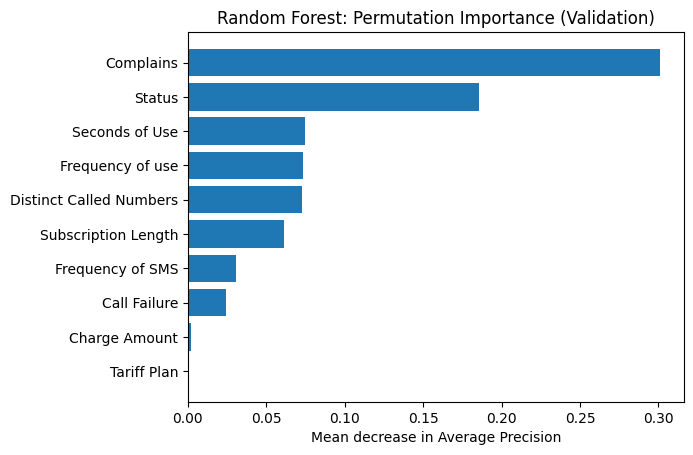

,feature,importance
6,Complains,0.301175
9,Status,0.185702
2,Seconds of Use,0.074424
3,Frequency of use,0.073701
5,Distinct Called Numbers,0.072844
1,Subscription Length,0.061521
4,Frequency of SMS,0.030741
0,Call Failure,0.024188
7,Charge Amount,0.002249
8,Tariff Plan,0.000531


In [15]:
# shuffle each feature 10 times and measure the drop in Average Precision
importance = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=SEED,
)
# put the feature names and their mean importance in a table
importance_table = pd.DataFrame({
    "feature": FEATURES,
    "importance": importance.importances_mean,
})
# sort the features from most to least important
importance_table = importance_table.sort_values("importance", ascending=False)
# draw the importance values as a horizontal bar chart
plt.barh(importance_table["feature"], importance_table["importance"])
# put the most important feature at the top
plt.gca().invert_yaxis()
# set the chart title
plt.title("Random Forest: Permutation Importance (Validation)")
# set the x-axis label
plt.xlabel("Mean decrease in Average Precision")
# save the chart as an image
plt.savefig(RESULTS_FOLDER + "/rf_permutation_importance.png", dpi=150, bbox_inches="tight")
# display the chart
plt.show()
# show the table
importance_table

### 15. Save the Results

<div dir="rtl" align="right">

تحفظ الخلية التالية نتائج الضبط، والمقاييس النهائية، وتوقعات الاختبار، وأهمية الخصائص في ملفات CSV ليستخدمها Notebook 4 في المقارنة.

</div>

In [16]:
# save the tuning table of the 12 configurations
tuning_sorted.drop(columns="depth_order").to_csv(RESULTS_FOLDER + "/rf_tuning_results.csv", index=False)
# put the final test metrics in a one-row table
metrics_table = pd.DataFrame([{
    "model": "Random Forest",
    "threshold": best_threshold,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "accuracy": accuracy,
    "average_precision": ap,
    "roc_auc": roc_auc,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
}])
# save the metrics table
metrics_table.to_csv(RESULTS_FOLDER + "/rf_metrics.csv", index=False)
# put the test predictions in a table
predictions_table = pd.DataFrame({
    "row_id": test["row_id"],
    "y_true": y_test,
    "probability": test_prob,
    "prediction": test_pred,
})
# save the predictions table
predictions_table.to_csv(RESULTS_FOLDER + "/rf_test_predictions.csv", index=False)
# save the feature importance table
importance_table.to_csv(RESULTS_FOLDER + "/rf_feature_importance.csv", index=False)
# confirm that the files were saved
print("Random Forest results saved in:", RESULTS_FOLDER)

Random Forest results saved in: /content/drive/MyDrive/churn_project/results
